In [ ]:
import sys
import tempfile
from pathlib import Path

import numpy as np

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "modulars").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from modulars.stan_rr_test import run_stan_random_restarts

max_iters = 500_000
# CmdStan only reports its final fit, so each tracked point is a separate rerun of the
# same seed stopped at that iteration; tracking every iteration would take hours
track_every = 10

STAN_FILE = REPO_ROOT / "single_MC/1dgaussian_knownvar/random_restarts/stan_1dgaussian_knownvar.stan"
OUTPUT_DIR = Path(tempfile.mkdtemp(prefix="3_1_stan_"))

In [7]:
mu_prior, sigma_prior = 0, 10
sigma_like = 1.0
# no observations, so the posterior is the N(mu_prior, sigma_prior^2) prior
stan_data = dict(N=0, y=np.array([]), sigma_like=sigma_like, mu_prior=mu_prior, sigma_prior=sigma_prior)


def run_stan(seed, cmd_args):
    """Every CmdStan ADVI default except iter, tol_rel_obj=1e-6 (so it runs all max_iters
    iterations instead of stopping at the default convergence tolerance) and 100,000 output draws
    (each tracked mean / std is computed from the draws; the default 1,000 would add visible noise)."""
    result = run_stan_random_restarts(
        stan_file=STAN_FILE, data=stan_data, param_columns=["mu"], output_dir=OUTPUT_DIR / f"seed_{seed}",
        max_iters=max_iters, n_restarts=1, track_every=track_every,
        scenarios=({"name": "run", "cmd_args": tuple(cmd_args) + ("output_samples=100000",), "tol_rel_obj": 1e-6},),
        seed_offset=seed, show_progress=False, dtype=np.float64,
    )
    assert not result["failures"], result["failures"]
    iterations = result["iterations_by_scenario"]["run"]
    means = np.ravel(result["means_by_scenario"]["run"])
    stds = np.ravel(result["stds_by_scenario"]["run"])
    return iterations, means, stds


# same seeds as 3_1_pymc.ipynb: 22 for the single MC sample run, 10 for the 100 MC sample run
single_iters, single_means, single_stds = run_stan(22, ())
multi_iters, multi_means, multi_stds = run_stan(10, ("grad_samples=100",))

python(28064) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28092) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28196) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28288) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28356) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28484) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28561) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28683) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28750) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28843) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(28922) Malloc

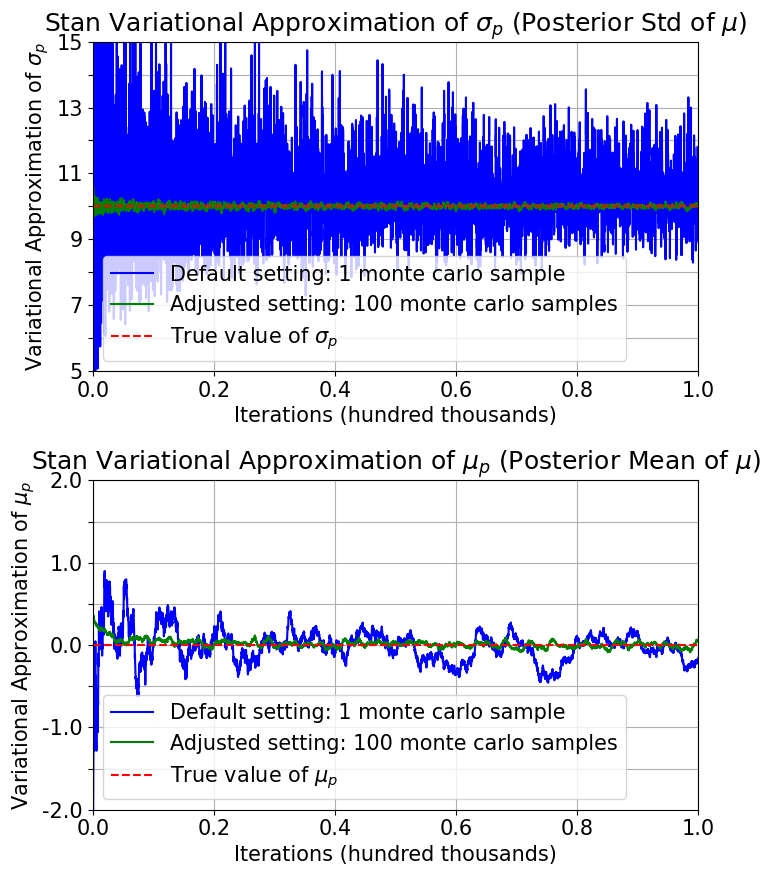

In [8]:
# plot single vs multi for the mean and std of mu
# add dashed lines for true values of mu mean and std which is N(0, 10)
from modulars.plot_rr import plot_3_1_trajectories
plot_3_1_trajectories(
    single_means,
    single_stds,
    multi_means,
    multi_stds,
    framework_name='Stan',
    max_iters=max_iters,
    true_mu=mu_prior, # since no observations, posterior is equal to prior
    true_sigma=sigma_prior,
    MILLIONS=False,
    iterations=single_iters,
    mean_ylim=(mu_prior - 2, mu_prior + 2),
    mean_yticks=[-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2],
    mean_y_labels=['-2.0', None, '-1.0', None, '0.0', None, '1.0', None, '2.0'],
    std_ylim=(sigma_prior - 5, sigma_prior + 5),
    std_yticks=[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    std_y_labels=['5', None, '7', None, '9', None, '11', None, '13', None, '15'],
)